# Pearson y Distance Correlation — EPM vs TPM

Cuaderno autocontenido: calcula correlacion de Pearson y distance correlation (Szekely, Rizzo & Bakirov 2007) entre las 14 series TPM y los 4 sensores EPM, por separado en la ventana **pre-brecha** (2022-11 a 2023-06, datos simultaneos reales) y en la ventana **post-brecha** (2025-05 en adelante, el EPM vuelve a medir). Usa directamente `Data_limpia_completa/{EPM,TPM}_completo.csv` (los CSV ya filtrados y limpios del proyecto), replicando el mismo esquema de alineacion temporal ya validado en `libro 1.ipynb` (merge_asof con tolerancia de 3h, rejilla de 6h en el tramo post-brecha).

Salidas: 4 heatmaps (Pearson pre, Pearson post, dCor pre, dCor post) guardados en `img/`, mas tablas de ranking para identificar facilmente que serie TPM se correlaciona mejor con cada sensor EPM, en cada ventana.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

IMG_DIR = Path('img')
IMG_DIR.mkdir(exist_ok=True)


## 1. Cargar datos y definir las dos ventanas

In [2]:
epm_raw = pd.read_csv('Data_limpia_completa/EPM_completo.csv', parse_dates=['date'])
tpm_raw = pd.read_csv('Data_limpia_completa/TPM_completo.csv', parse_dates=['date'])

BRECHA_INICIO = pd.Timestamp('2023-06-20')
BRECHA_FIN = pd.Timestamp('2025-05-01')

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']

print(f"EPM: {epm_raw.shape}, rango {epm_raw['date'].min()} -> {epm_raw['date'].max()}")
print(f"TPM: {tpm_raw.shape}, rango {tpm_raw['date'].min()} -> {tpm_raw['date'].max()}")


EPM: (7245, 5), rango 2022-11-09 19:00:00 -> 2025-09-15 14:30:00
TPM: (10379, 16), rango 2017-12-04 12:30:00 -> 2025-10-10 18:00:00


### Ventana pre-brecha

`merge_asof` con tolerancia de 3h (igual que `libro 1.ipynb`, celda de construccion de `df_ccm`): EPM y TPM tienen desfases de rejilla documentados (1h-17h segun el bloque), asi que no se usa un join exacto por fecha.

In [3]:
epm_pre = epm_raw[epm_raw['date'] < BRECHA_INICIO].sort_values('date')
tpm_pre = tpm_raw[tpm_raw['date'] < BRECHA_INICIO].drop(columns=['freq']).sort_values('date')

df_pre = pd.merge_asof(
    epm_pre, tpm_pre, on='date', direction='nearest', tolerance=pd.Timedelta('3h')
)
df_pre = df_pre.dropna().reset_index(drop=True)

print(f"Filas pre-brecha alineadas: {len(df_pre)}  "
      f"({df_pre['date'].min()} -> {df_pre['date'].max()})")


Filas pre-brecha alineadas: 885  (2022-11-09 19:00:00 -> 2023-06-19 19:00:00)


### Ventana post-brecha

Rejilla regular de 6h desde el fin de la brecha hasta el final del registro, con `merge_asof` (tolerancia 3h) para EPM y TPM por separado, luego interseccion exacta por fecha (mismo esquema que `libro 1.ipynb`, celda de `df_ccm_post`).

In [4]:
rejilla_post = pd.DataFrame({
    'date': pd.date_range(BRECHA_FIN, epm_raw['date'].max(), freq='6h')
})

epm_post = pd.merge_asof(
    rejilla_post, epm_raw.sort_values('date'),
    on='date', direction='nearest', tolerance=pd.Timedelta('3h')
).dropna().reset_index(drop=True)

tpm_post = pd.merge_asof(
    rejilla_post, tpm_raw.drop(columns=['freq']).sort_values('date'),
    on='date', direction='nearest', tolerance=pd.Timedelta('3h')
).dropna().reset_index(drop=True)

df_post = pd.merge(epm_post, tpm_post, on='date', how='inner')

paso_horas = (df_post['date'].iloc[1] - df_post['date'].iloc[0]).total_seconds() / 3600
print(f"Filas post-brecha alineadas: {len(df_post)}  "
      f"({df_post['date'].min()} -> {df_post['date'].max()})  paso={paso_horas}h")
assert paso_horas == 6.0, "El remuestreo post-brecha no quedo en 6h -- revisar"

df_pre_sf = df_pre.drop(columns=['date'])
df_post_sf = df_post.drop(columns=['date'])


Filas post-brecha alineadas: 492  (2025-05-01 00:00:00 -> 2025-09-15 00:00:00)  paso=6.0h


## 2. Pearson y Distance Correlation

In [5]:
def distance_correlation(x, y):
    """
    Distance correlation de Szekely, Rizzo & Bakirov (2007), via doble centrado.
    O(n^2) en memoria -- aceptable para n del orden de cientos (estas dos ventanas),
    no para series completas de alta frecuencia.
    """
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(-1, 1)

    a = np.abs(x - x.T)
    b = np.abs(y - y.T)

    A = a - a.mean(axis=0, keepdims=True) - a.mean(axis=1, keepdims=True) + a.mean()
    B = b - b.mean(axis=0, keepdims=True) - b.mean(axis=1, keepdims=True) + b.mean()

    dcov2 = (A * B).mean()
    dvarx2 = (A * A).mean()
    dvary2 = (B * B).mean()
    denom = np.sqrt(dvarx2 * dvary2)
    return float(np.sqrt(dcov2 / denom)) if denom > 0 else 0.0


def matriz_pearson_dcor(df, series_tpm, series_epm):
    filas = []
    for tpm_col in series_tpm:
        for epm_col in series_epm:
            x = df[tpm_col].values
            y = df[epm_col].values
            r = float(np.corrcoef(x, y)[0, 1])
            dc = distance_correlation(x, y)
            filas.append({'TPM': tpm_col, 'EPM': epm_col, 'pearson_r': r, 'dcor': dc})
    return pd.DataFrame(filas)


pre_dcor_df = matriz_pearson_dcor(df_pre_sf, series_tpm, series_epm)
post_dcor_df = matriz_pearson_dcor(df_post_sf, series_tpm, series_epm)
print('Pre-brecha:', len(pre_dcor_df), 'pares  |  Post-brecha:', len(post_dcor_df), 'pares')


Pre-brecha: 56 pares  |  Post-brecha: 56 pares


## 3. Heatmaps (uno por métrica, uno por ventana)

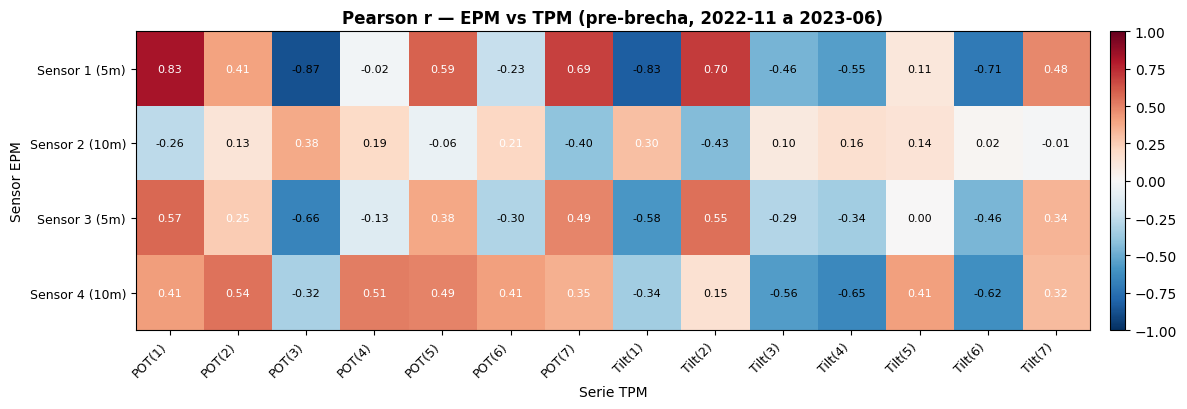

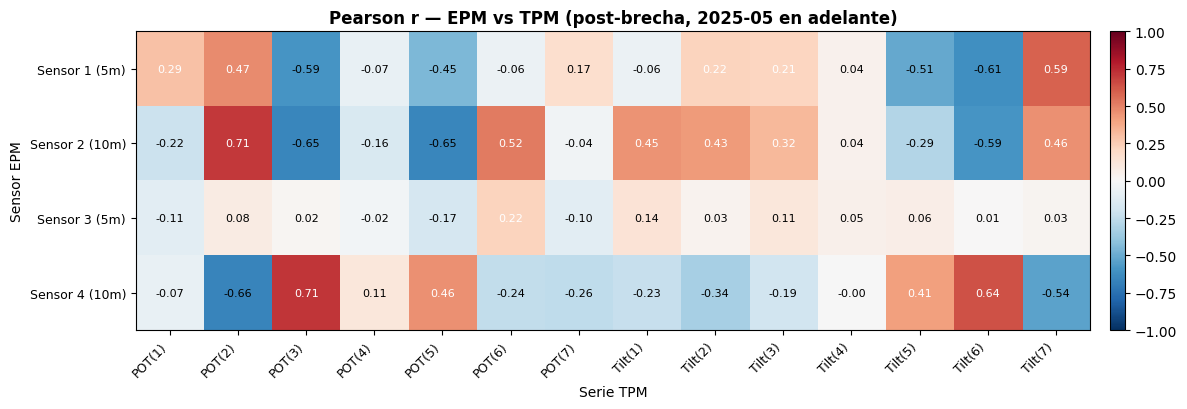

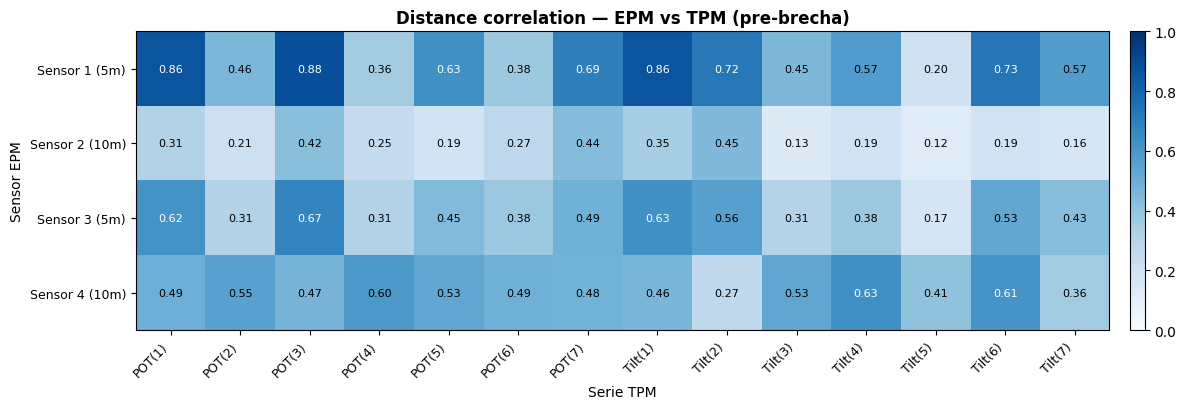

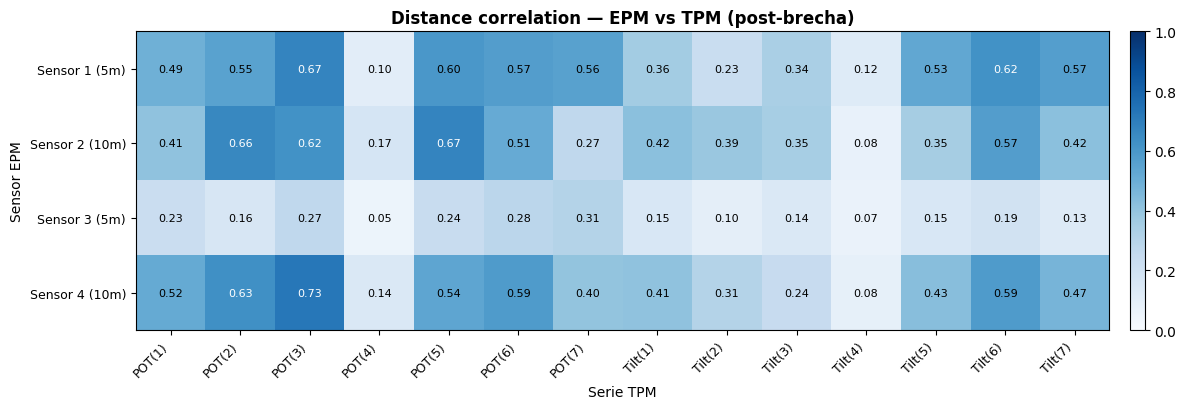

In [6]:
def pivotear(df_largo, columna_valor):
    return df_largo.pivot(index='EPM', columns='TPM', values=columna_valor).reindex(
        index=series_epm, columns=series_tpm
    )


def graficar_heatmap(matriz, titulo, archivo, cmap, vmin=None, vmax=None, fmt='.2f'):
    fig, ax = plt.subplots(figsize=(12, 4.2))
    im = ax.imshow(matriz.values, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.values[i, j]
            color_txt = 'white' if abs(valor - (vmin or 0)) / ((vmax or 1) - (vmin or 0) + 1e-9) > 0.6 else 'black'
            ax.text(j, i, f'{valor:{fmt}}', ha='center', va='center', fontsize=8, color=color_txt)

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index, fontsize=9)
    ax.set_xlabel('Serie TPM', fontsize=10)
    ax.set_ylabel('Sensor EPM', fontsize=10)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(IMG_DIR / archivo, dpi=150)
    plt.show()


mat_pearson_pre = pivotear(pre_dcor_df, 'pearson_r')
mat_pearson_post = pivotear(post_dcor_df, 'pearson_r')
mat_dcor_pre = pivotear(pre_dcor_df, 'dcor')
mat_dcor_post = pivotear(post_dcor_df, 'dcor')

graficar_heatmap(mat_pearson_pre, 'Pearson r — EPM vs TPM (pre-brecha, 2022-11 a 2023-06)',
                  'heatmap_pearson_pre.png', cmap='RdBu_r', vmin=-1, vmax=1)
graficar_heatmap(mat_pearson_post, 'Pearson r — EPM vs TPM (post-brecha, 2025-05 en adelante)',
                  'heatmap_pearson_post.png', cmap='RdBu_r', vmin=-1, vmax=1)
graficar_heatmap(mat_dcor_pre, 'Distance correlation — EPM vs TPM (pre-brecha)',
                  'heatmap_dcor_pre.png', cmap='Blues', vmin=0, vmax=1)
graficar_heatmap(mat_dcor_post, 'Distance correlation — EPM vs TPM (post-brecha)',
                  'heatmap_dcor_post.png', cmap='Blues', vmin=0, vmax=1)


## 4. ¿Qué serie TPM informa mejor a cada sensor EPM?

Tabla compacta (el mejor TPM por sensor EPM, en cada ventana y métrica) y, debajo, el ranking completo de las 14 series por sensor EPM y ventana, para ver no solo la mejor sino todo el orden.

In [7]:
def mejor_por_epm(df_largo, columna_valor, usar_abs=False):
    filas = []
    for epm_col in series_epm:
        sub = df_largo[df_largo['EPM'] == epm_col].copy()
        clave = sub[columna_valor].abs() if usar_abs else sub[columna_valor]
        fila = sub.loc[clave.idxmax()]
        filas.append({'EPM': epm_col, 'TPM_mejor': fila['TPM'], 'valor': fila[columna_valor]})
    return pd.DataFrame(filas)


resumen = mejor_por_epm(pre_dcor_df, 'pearson_r', usar_abs=True).rename(
    columns={'TPM_mejor': 'TPM_mejor_pearson_pre', 'valor': 'pearson_pre'}
)
resumen = resumen.merge(
    mejor_por_epm(post_dcor_df, 'pearson_r', usar_abs=True).rename(
        columns={'TPM_mejor': 'TPM_mejor_pearson_post', 'valor': 'pearson_post'}
    ), on='EPM'
)
resumen = resumen.merge(
    mejor_por_epm(pre_dcor_df, 'dcor').rename(
        columns={'TPM_mejor': 'TPM_mejor_dcor_pre', 'valor': 'dcor_pre'}
    ), on='EPM'
)
resumen = resumen.merge(
    mejor_por_epm(post_dcor_df, 'dcor').rename(
        columns={'TPM_mejor': 'TPM_mejor_dcor_post', 'valor': 'dcor_post'}
    ), on='EPM'
)

display(resumen.round(3))


,EPM,TPM_mejor_pearson_pre,pearson_pre,TPM_mejor_pearson_post,pearson_post,TPM_mejor_dcor_pre,dcor_pre,TPM_mejor_dcor_post,dcor_post
0,Sensor 1 (5m),POT(3),-0.869,Tilt(6),-0.612,POT(3),0.880,POT(3),0.675
1,Sensor 2 (10m),Tilt(2),-0.433,POT(2),0.710,Tilt(2),0.446,POT(5),0.674
2,Sensor 3 (5m),POT(3),-0.659,POT(6),0.224,POT(3),0.674,POT(7),0.305
3,Sensor 4 (10m),Tilt(4),-0.648,POT(3),0.715,Tilt(4),0.630,POT(3),0.726


In [8]:
for epm_col in series_epm:
    print('=' * 70)
    print(f'{epm_col} — ranking de las 14 series TPM')
    print('=' * 70)

    ranking_pre = pre_dcor_df[pre_dcor_df['EPM'] == epm_col][['TPM', 'pearson_r', 'dcor']]
    ranking_pre = ranking_pre.sort_values('dcor', ascending=False).reset_index(drop=True)
    print('--- pre-brecha (ordenado por dCor) ---')
    display(ranking_pre.round(3))

    ranking_post = post_dcor_df[post_dcor_df['EPM'] == epm_col][['TPM', 'pearson_r', 'dcor']]
    ranking_post = ranking_post.sort_values('dcor', ascending=False).reset_index(drop=True)
    print('--- post-brecha (ordenado por dCor) ---')
    display(ranking_post.round(3))
    print()


Sensor 1 (5m) — ranking de las 14 series TPM
--- pre-brecha (ordenado por dCor) ---


,TPM,pearson_r,dcor
0,POT(3),-0.869,0.880
1,POT(1),0.826,0.858
2,Tilt(1),-0.826,0.856
3,Tilt(6),-0.706,0.734
4,Tilt(2),0.703,0.719
5,POT(7),0.686,0.695
6,POT(5),0.592,0.626
7,Tilt(4),-0.547,0.575
8,Tilt(7),0.479,0.572
9,POT(2),0.406,0.458


--- post-brecha (ordenado por dCor) ---


,TPM,pearson_r,dcor
0,POT(3),-0.587,0.675
1,Tilt(6),-0.612,0.622
2,POT(5),-0.452,0.600
3,POT(6),-0.061,0.571
4,Tilt(7),0.592,0.568
5,POT(7),0.165,0.558
6,POT(2),0.470,0.551
7,Tilt(5),-0.514,0.528
8,POT(1),0.293,0.492
9,Tilt(1),-0.056,0.356



Sensor 2 (10m) — ranking de las 14 series TPM
--- pre-brecha (ordenado por dCor) ---


...

,TPM,pearson_r,dcor
0,POT(7),-0.102,0.305
1,POT(6),0.224,0.283
2,POT(3),0.020,0.266
3,POT(5),-0.171,0.238
4,POT(1),-0.108,0.229
5,Tilt(6),0.006,0.195
6,POT(2),0.081,0.162
7,Tilt(5),0.063,0.155
8,Tilt(1),0.135,0.153
9,Tilt(3),0.114,0.142



Sensor 4 (10m) — ranking de las 14 series TPM
--- pre-brecha (ordenado por dCor) ---


,TPM,pearson_r,dcor
0,Tilt(4),-0.648,0.630
1,Tilt(6),-0.616,0.613
2,POT(4),0.514,0.595
3,POT(2),0.545,0.554
4,Tilt(3),-0.559,0.533
5,POT(5),0.493,0.530
6,POT(1),0.415,0.493
7,POT(6),0.413,0.489
8,POT(7),0.352,0.480
9,POT(3),-0.322,0.470


--- post-brecha (ordenado por dCor) ---


,TPM,pearson_r,dcor
0,POT(3),0.715,0.726
1,POT(2),-0.658,0.631
2,POT(6),-0.244,0.585
3,Tilt(6),0.640,0.585
4,POT(5),0.459,0.539
5,POT(1),-0.073,0.518
6,Tilt(7),-0.538,0.469
7,Tilt(5),0.409,0.426
8,Tilt(1),-0.227,0.409
9,POT(7),-0.256,0.400
